In [89]:
import pandas as pd
import torch 
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch.optim as optim
import matplotlib.pyplot as plt
from torchmetrics import MetricCollection, R2Score, MeanAbsoluteError, MeanSquaredError

In [90]:
df = pd.read_csv("hourly_wages_data.csv")
print(df.head())

   wage_per_hour  union  education_yrs  experience_yrs  age  female  marr  \
0           5.10      0              8              21   35       1     1   
1           4.95      0              9              42   57       1     1   
2           6.67      0             12               1   19       0     0   
3           4.00      0             12               4   22       0     0   
4           7.50      0             12              17   35       0     1   

   south  manufacturing  construction  
0      0              1             0  
1      0              1             0  
2      0              1             0  
3      0              0             0  
4      0              0             0  


In [91]:
X = df.drop("wage_per_hour", axis = 1)
y = df["wage_per_hour"]
print(X.head())
print(y.head())

   union  education_yrs  experience_yrs  age  female  marr  south  \
0      0              8              21   35       1     1      0   
1      0              9              42   57       1     1      0   
2      0             12               1   19       0     0      0   
3      0             12               4   22       0     0      0   
4      0             12              17   35       0     1      0   

   manufacturing  construction  
0              1             0  
1              1             0  
2              1             0  
3              0             0  
4              0             0  
0    5.10
1    4.95
2    6.67
3    4.00
4    7.50
Name: wage_per_hour, dtype: float64


In [92]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.22, random_state=42)

In [93]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [94]:
X_train_scaled_tensor = torch.tensor(X_train_scaled, dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values.reshape(-1,1), dtype=torch.float32)
X_val_scaled_tensor = torch.tensor(X_val_scaled, dtype = torch.float32)
y_val_tensor = torch.tensor(y_val.values.reshape(-1,1), dtype=torch.float32)
X_test_scaled_tensor = torch.tensor(X_test_scaled, dtype = torch.float32)
y_test_tensor = torch.tensor(y_test.values.reshape(-1,1), dtype=torch.float32)

input_dim = X.shape[1]
print(input_dim)

9


In [95]:
class MultiLayerPerceptronRegressor(nn.Module):
    def __init__(self, input_dimension, activation_function = nn.ReLU):
        super(MultiLayerPerceptronRegressor, self).__init__()
        self.fc1 = nn.Linear(input_dimension, 10)
        self.fc2 = nn.Linear(10,10)
        self.output = nn.Linear(10,1)
        self.relu = activation_function()
        
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.output(x)
        return x


In [96]:
# class MultiLayerPerceptronRegressor(nn.Module):
#     def __init__(self, input_dimension, activation_function = nn.ReLU):
#         super(MultiLayerPerceptronRegressor, self).__init__()
#         self.fc1 = nn.Linear(input_dimension, 200)
#         self.fc2 = nn.Linear(200,200)
#         self.fc3 = nn.Linear(200,200)
#         self.output = nn.Linear(200,1)
#         self.relu = activation_function()
#         
#     def forward(self, x):
#         x = self.relu(self.fc1(x))
#         x = self.relu(self.fc2(x))
#         x = self.output(x)
#         return x


In [97]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0, restore_best_weights=True):
        self.patience = patience 
        self.min_delta = min_delta 
        self.restore_best_weights = restore_best_weights 
        self.best_loss = None
        self.counter = 0
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model_state = model.state_dict()
            self.counter = 0

In [98]:
def perform_learning(epochs, optimizer_name, activation_function_name, early_stopping_enabled = True):
    activations = {'ReLU': nn.ReLU, 'Sigmoid': nn.Sigmoid, 'Tanh': nn.Tanh}
    activation_function = activations[activation_function_name]
    model = MultiLayerPerceptronRegressor(input_dim, activation_function)
    early_stopping = EarlyStopping(patience=50)
    optimizers = {
    'SGD': optim.SGD(model.parameters(), lr=0.01),
    'RMSprop': optim.RMSprop(model.parameters(), lr=0.01),
    'Adam': optim.Adam(model.parameters(), lr=0.01),
    'Adadelta': optim.Adadelta(model.parameters(), lr=1.0),
    'Adagrad': optim.Adagrad(model.parameters(), lr=0.01),
    'Adamax': optim.Adamax(model.parameters(), lr=0.01),
    'Nadam': optim.NAdam(model.parameters(), lr=0.01)
    }
    criterion = nn.MSELoss()    
    train_loss_history = []
    val_loss_history = []
    optimizer = optimizers[optimizer_name]
    metrics = MetricCollection({
        "r2": R2Score(),
        "mae": MeanAbsoluteError(),
        "mse": MeanSquaredError()
        
    })
    already_stopped = False
    
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        train_predictions = model(X_train_scaled_tensor)
        train_loss = criterion(train_predictions, y_train_tensor)
        train_loss.backward()
        optimizer.step()
        train_loss_history.append(train_loss.item())
        
        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_scaled_tensor)
            val_loss = criterion(val_predictions, y_val_tensor)
            if not already_stopped:
                step_metrics = metrics(val_predictions, y_val_tensor)
            early_stopping(val_loss.item(), model)
            val_loss_history.append(val_loss.item())
            
        if early_stopping.early_stop and early_stopping_enabled and not already_stopped:
            print(f"--- [INFO] Early stopping triggered at epoch {epoch+1} for {optimizer_name} ---")
            already_stopped = True
                    
        if((epoch + 1) % 50 == 0):
            print(f'Optimizer: {optimizer_name}, Function: {activation_function_name}, Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss.item():.4f}, Validation Loss: {val_loss.item():.4f}')
            
    if early_stopping.restore_best_weights:
        model.load_state_dict(early_stopping.best_model_state)  
    return train_loss_history, val_loss_history, step_metrics, model

In [99]:
optimizer_names = ['SGD', 'RMSprop', 'Adam', 'Adadelta', 'Adagrad', 'Adamax', 'Nadam']
activation_function_names = ['ReLU', 'Sigmoid', 'Tanh']
results = []
best_model = None
best_mse = float('inf')

Optimizer: SGD, Function: ReLU, Epoch [50/1000], Train Loss: 18.5253, Validation Loss: 14.6112
--- [INFO] Early stopping triggered at epoch 96 for SGD ---
Optimizer: SGD, Function: ReLU, Epoch [100/1000], Train Loss: 18.1109, Validation Loss: 14.7471
Optimizer: SGD, Function: ReLU, Epoch [150/1000], Train Loss: 17.8476, Validation Loss: 14.7468
Optimizer: SGD, Function: ReLU, Epoch [200/1000], Train Loss: 17.5649, Validation Loss: 14.7163
Optimizer: SGD, Function: ReLU, Epoch [250/1000], Train Loss: 17.2731, Validation Loss: 14.7815
Optimizer: SGD, Function: ReLU, Epoch [300/1000], Train Loss: 17.0694, Validation Loss: 14.8992
Optimizer: SGD, Function: ReLU, Epoch [350/1000], Train Loss: 16.8927, Validation Loss: 14.7793
Optimizer: SGD, Function: ReLU, Epoch [400/1000], Train Loss: 16.7542, Validation Loss: 14.6455
Optimizer: SGD, Function: ReLU, Epoch [450/1000], Train Loss: 16.6509, Validation Loss: 14.7427
Optimizer: SGD, Function: ReLU, Epoch [500/1000], Train Loss: 16.5598, Valida

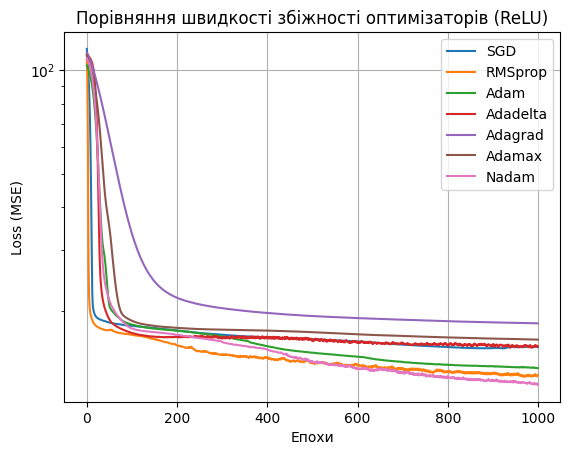

Optimizer: SGD, Function: Sigmoid, Epoch [50/1000], Train Loss: 26.3113, Validation Loss: 17.0924
Optimizer: SGD, Function: Sigmoid, Epoch [100/1000], Train Loss: 25.4708, Validation Loss: 16.4725
Optimizer: SGD, Function: Sigmoid, Epoch [150/1000], Train Loss: 24.4072, Validation Loss: 15.6462
Optimizer: SGD, Function: Sigmoid, Epoch [200/1000], Train Loss: 23.1067, Validation Loss: 14.6276
Optimizer: SGD, Function: Sigmoid, Epoch [250/1000], Train Loss: 21.7560, Validation Loss: 13.6180
Optimizer: SGD, Function: Sigmoid, Epoch [300/1000], Train Loss: 20.6663, Validation Loss: 12.9050
Optimizer: SGD, Function: Sigmoid, Epoch [350/1000], Train Loss: 19.9809, Validation Loss: 12.5883
Optimizer: SGD, Function: Sigmoid, Epoch [400/1000], Train Loss: 19.6104, Validation Loss: 12.5555
--- [INFO] Early stopping triggered at epoch 432 for SGD ---
Optimizer: SGD, Function: Sigmoid, Epoch [450/1000], Train Loss: 19.4120, Validation Loss: 12.6500
Optimizer: SGD, Function: Sigmoid, Epoch [500/100

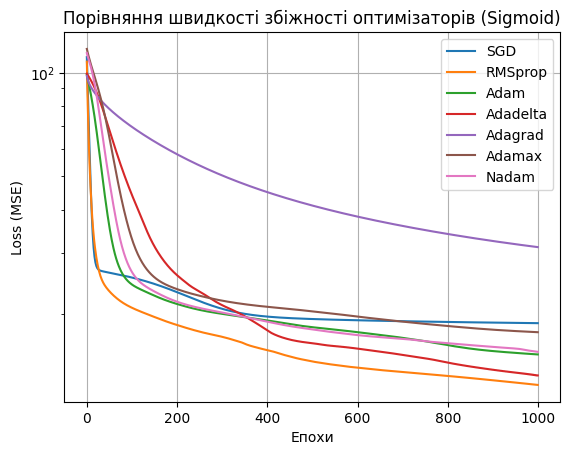

Optimizer: SGD, Function: Tanh, Epoch [50/1000], Train Loss: 21.0629, Validation Loss: 12.5114
Optimizer: SGD, Function: Tanh, Epoch [100/1000], Train Loss: 19.3365, Validation Loss: 12.3178
Optimizer: SGD, Function: Tanh, Epoch [150/1000], Train Loss: 18.4599, Validation Loss: 12.2289
Optimizer: SGD, Function: Tanh, Epoch [200/1000], Train Loss: 17.8378, Validation Loss: 12.4525
--- [INFO] Early stopping triggered at epoch 205 for SGD ---
Optimizer: SGD, Function: Tanh, Epoch [250/1000], Train Loss: 17.3749, Validation Loss: 13.0293
Optimizer: SGD, Function: Tanh, Epoch [300/1000], Train Loss: 16.9850, Validation Loss: 13.5985
Optimizer: SGD, Function: Tanh, Epoch [350/1000], Train Loss: 16.6141, Validation Loss: 14.0250
Optimizer: SGD, Function: Tanh, Epoch [400/1000], Train Loss: 16.2441, Validation Loss: 14.3628
Optimizer: SGD, Function: Tanh, Epoch [450/1000], Train Loss: 15.9082, Validation Loss: 14.7066
Optimizer: SGD, Function: Tanh, Epoch [500/1000], Train Loss: 15.6199, Valid

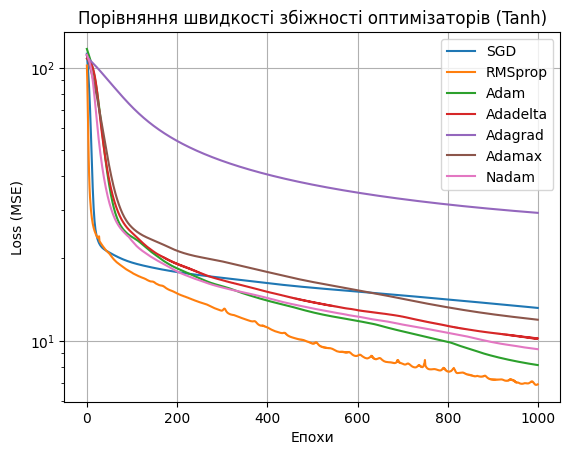

In [100]:
for activation_function_name in activation_function_names:
    for optimizer in optimizer_names:
        train_loss_history, val_loss_history, final_metrics, model = perform_learning(1000, optimizer, activation_function_name)
        current_mse = final_metrics["mse"].item()
        if current_mse < best_mse:
            best_mse = current_mse
            best_model = model
        plt.plot(train_loss_history, label=optimizer)
        results.append({
            'Activation': activation_function_name,
            'Optimizer': optimizer,
            'MSE': current_mse,
            'R2-Score': final_metrics['r2'].item()
        })
     
    plt.title(f'Порівняння швидкості збіжності оптимізаторів ({activation_function_name})')
    plt.xlabel('Епохи')
    plt.ylabel('Loss (MSE)')
    plt.yscale('log')  
    plt.legend()
    plt.grid(True)
    plt.show()

In [101]:
results_df = pd.DataFrame(results)
print(results_df.sort_values(by='R2-Score', ascending=False))

   Activation Optimizer        MSE  R2-Score
12    Sigmoid    Adamax  11.625456  0.317216
9     Sigmoid      Adam  11.883797  0.302043
13    Sigmoid     Nadam  11.967192  0.297145
16       Tanh      Adam  12.196157  0.283698
8     Sigmoid   RMSprop  12.331122  0.275771
17       Tanh  Adadelta  12.428507  0.270051
14       Tanh       SGD  12.501660  0.265755
10    Sigmoid  Adadelta  12.511224  0.265193
7     Sigmoid       SGD  12.609131  0.259443
19       Tanh    Adamax  12.748199  0.251275
20       Tanh     Nadam  13.094673  0.230926
15       Tanh   RMSprop  13.100023  0.230612
2        ReLU      Adam  14.726713  0.135073
0        ReLU       SGD  14.740824  0.134245
6        ReLU     Nadam  14.925105  0.123421
3        ReLU  Adadelta  15.050781  0.116040
5        ReLU    Adamax  15.096406  0.113361
4        ReLU   Adagrad  15.218263  0.106204
1        ReLU   RMSprop  15.765986  0.074035
18       Tanh   Adagrad  18.031181 -0.059004
11    Sigmoid   Adagrad  19.360384 -0.137071


In [102]:
def perform_learning_analysis(epochs, optimizer_name, activation_function_name):
    train_loss_history, val_loss_history, _, _ = perform_learning(epochs, optimizer_name, activation_function_name)
    plt.figure(figsize=(10, 6))
    plt.plot(train_loss_history, label='Train Loss')
    plt.plot(val_loss_history, label='Validation Loss', linestyle='--')
    plt.title(f'Аналіз перенавчання ({optimizer_name} + {activation_function_name})')
    plt.xlabel('Епохи')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

Optimizer: SGD, Function: ReLU, Epoch [50/1000], Train Loss: 18.5240, Validation Loss: 14.5944
--- [INFO] Early stopping triggered at epoch 61 for SGD ---
Optimizer: SGD, Function: ReLU, Epoch [100/1000], Train Loss: 18.1662, Validation Loss: 14.6447
Optimizer: SGD, Function: ReLU, Epoch [150/1000], Train Loss: 17.9709, Validation Loss: 14.7451
Optimizer: SGD, Function: ReLU, Epoch [200/1000], Train Loss: 17.8231, Validation Loss: 14.7082
Optimizer: SGD, Function: ReLU, Epoch [250/1000], Train Loss: 17.6799, Validation Loss: 14.6041
Optimizer: SGD, Function: ReLU, Epoch [300/1000], Train Loss: 17.5618, Validation Loss: 14.5999
Optimizer: SGD, Function: ReLU, Epoch [350/1000], Train Loss: 17.4269, Validation Loss: 14.5825
Optimizer: SGD, Function: ReLU, Epoch [400/1000], Train Loss: 17.3152, Validation Loss: 14.4893
Optimizer: SGD, Function: ReLU, Epoch [450/1000], Train Loss: 17.1912, Validation Loss: 14.5081
Optimizer: SGD, Function: ReLU, Epoch [500/1000], Train Loss: 17.0856, Valida

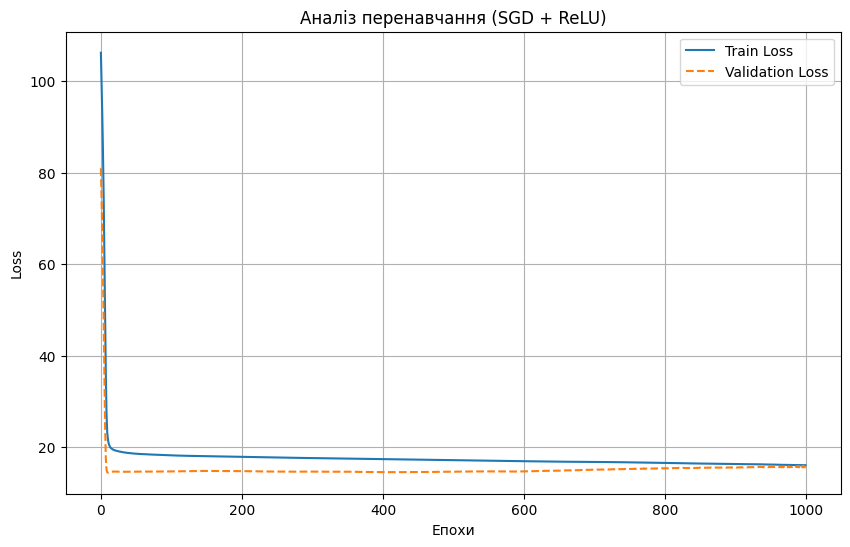

Optimizer: RMSprop, Function: ReLU, Epoch [50/1000], Train Loss: 17.8850, Validation Loss: 16.0313
Optimizer: RMSprop, Function: ReLU, Epoch [100/1000], Train Loss: 17.7219, Validation Loss: 15.9635
Optimizer: RMSprop, Function: ReLU, Epoch [150/1000], Train Loss: 17.6425, Validation Loss: 15.7418
Optimizer: RMSprop, Function: ReLU, Epoch [200/1000], Train Loss: 17.5899, Validation Loss: 15.6419
Optimizer: RMSprop, Function: ReLU, Epoch [250/1000], Train Loss: 17.5405, Validation Loss: 15.6167
--- [INFO] Early stopping triggered at epoch 257 for RMSprop ---
Optimizer: RMSprop, Function: ReLU, Epoch [300/1000], Train Loss: 17.4793, Validation Loss: 15.4963
Optimizer: RMSprop, Function: ReLU, Epoch [350/1000], Train Loss: 17.3473, Validation Loss: 15.7664
Optimizer: RMSprop, Function: ReLU, Epoch [400/1000], Train Loss: 17.2377, Validation Loss: 16.1135
Optimizer: RMSprop, Function: ReLU, Epoch [450/1000], Train Loss: 17.1962, Validation Loss: 16.5382
Optimizer: RMSprop, Function: ReLU, 

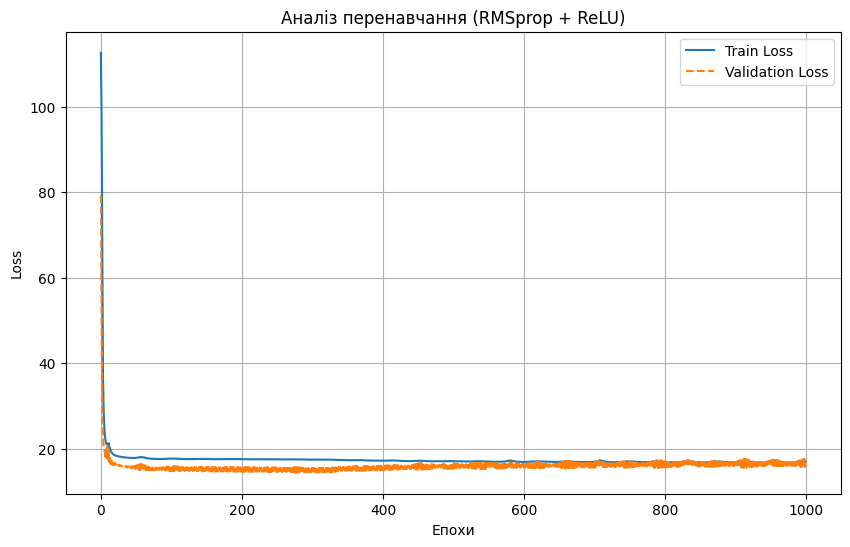

Optimizer: Adam, Function: ReLU, Epoch [50/1000], Train Loss: 20.2852, Validation Loss: 17.1512
Optimizer: Adam, Function: ReLU, Epoch [100/1000], Train Loss: 18.0753, Validation Loss: 15.6384
Optimizer: Adam, Function: ReLU, Epoch [150/1000], Train Loss: 17.5169, Validation Loss: 15.0751
Optimizer: Adam, Function: ReLU, Epoch [200/1000], Train Loss: 16.9475, Validation Loss: 15.6779
--- [INFO] Early stopping triggered at epoch 207 for Adam ---
Optimizer: Adam, Function: ReLU, Epoch [250/1000], Train Loss: 16.4784, Validation Loss: 15.7807
Optimizer: Adam, Function: ReLU, Epoch [300/1000], Train Loss: 16.3081, Validation Loss: 15.9526
Optimizer: Adam, Function: ReLU, Epoch [350/1000], Train Loss: 16.2098, Validation Loss: 16.2386
Optimizer: Adam, Function: ReLU, Epoch [400/1000], Train Loss: 16.0812, Validation Loss: 16.6481
Optimizer: Adam, Function: ReLU, Epoch [450/1000], Train Loss: 16.0102, Validation Loss: 16.9056
Optimizer: Adam, Function: ReLU, Epoch [500/1000], Train Loss: 15.

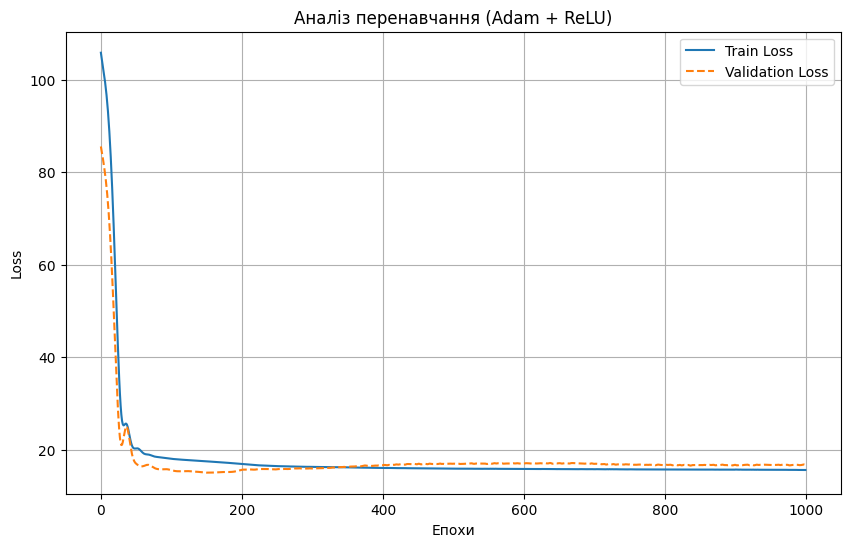

Optimizer: Adadelta, Function: ReLU, Epoch [50/1000], Train Loss: 21.2829, Validation Loss: 16.7464
Optimizer: Adadelta, Function: ReLU, Epoch [100/1000], Train Loss: 18.3474, Validation Loss: 14.4465
Optimizer: Adadelta, Function: ReLU, Epoch [150/1000], Train Loss: 17.7474, Validation Loss: 14.1774
--- [INFO] Early stopping triggered at epoch 192 for Adadelta ---
Optimizer: Adadelta, Function: ReLU, Epoch [200/1000], Train Loss: 17.4902, Validation Loss: 14.2266
Optimizer: Adadelta, Function: ReLU, Epoch [250/1000], Train Loss: 17.4617, Validation Loss: 14.3831
Optimizer: Adadelta, Function: ReLU, Epoch [300/1000], Train Loss: 17.3278, Validation Loss: 14.4208
Optimizer: Adadelta, Function: ReLU, Epoch [350/1000], Train Loss: 17.3970, Validation Loss: 14.6069
Optimizer: Adadelta, Function: ReLU, Epoch [400/1000], Train Loss: 17.2440, Validation Loss: 14.8902
Optimizer: Adadelta, Function: ReLU, Epoch [450/1000], Train Loss: 17.2047, Validation Loss: 15.0367
Optimizer: Adadelta, Funct

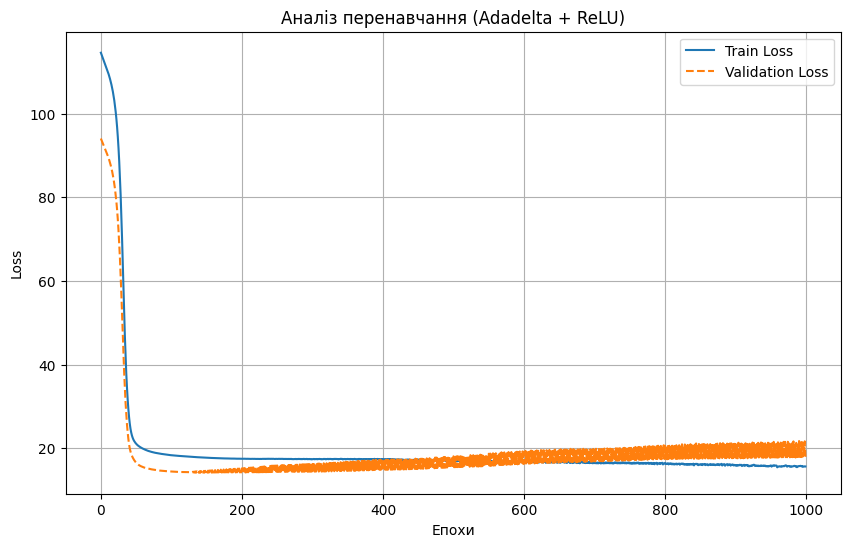

Optimizer: Adagrad, Function: ReLU, Epoch [50/1000], Train Loss: 63.9367, Validation Loss: 48.2339
Optimizer: Adagrad, Function: ReLU, Epoch [100/1000], Train Loss: 34.2262, Validation Loss: 25.3215
Optimizer: Adagrad, Function: ReLU, Epoch [150/1000], Train Loss: 24.4454, Validation Loss: 19.8677
Optimizer: Adagrad, Function: ReLU, Epoch [200/1000], Train Loss: 21.8811, Validation Loss: 19.0051
Optimizer: Adagrad, Function: ReLU, Epoch [250/1000], Train Loss: 20.9723, Validation Loss: 18.5010
Optimizer: Adagrad, Function: ReLU, Epoch [300/1000], Train Loss: 20.4845, Validation Loss: 18.0063
Optimizer: Adagrad, Function: ReLU, Epoch [350/1000], Train Loss: 20.1220, Validation Loss: 17.5304
Optimizer: Adagrad, Function: ReLU, Epoch [400/1000], Train Loss: 19.7512, Validation Loss: 17.0115
Optimizer: Adagrad, Function: ReLU, Epoch [450/1000], Train Loss: 19.4767, Validation Loss: 16.6163
Optimizer: Adagrad, Function: ReLU, Epoch [500/1000], Train Loss: 19.2526, Validation Loss: 16.2808
O

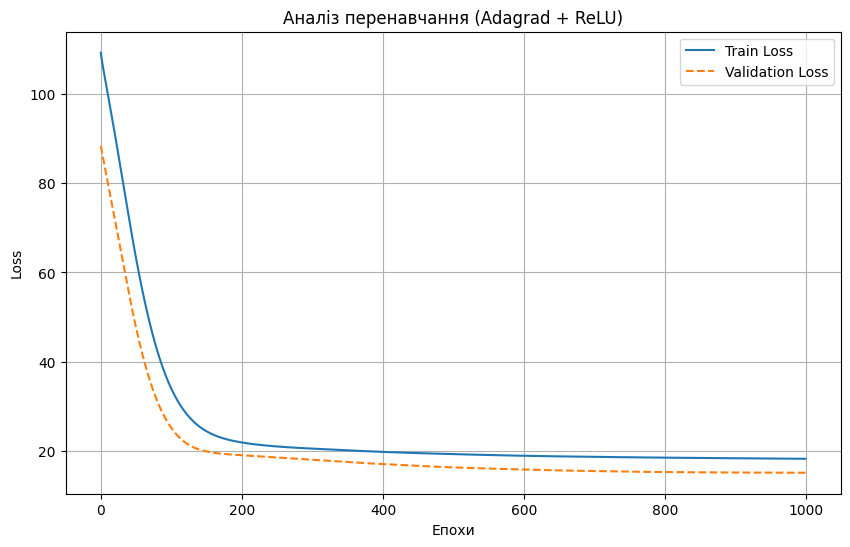

Optimizer: Adamax, Function: ReLU, Epoch [50/1000], Train Loss: 26.1034, Validation Loss: 19.2103
Optimizer: Adamax, Function: ReLU, Epoch [100/1000], Train Loss: 18.8502, Validation Loss: 16.0167
--- [INFO] Early stopping triggered at epoch 132 for Adamax ---
Optimizer: Adamax, Function: ReLU, Epoch [150/1000], Train Loss: 18.2239, Validation Loss: 15.5223
Optimizer: Adamax, Function: ReLU, Epoch [200/1000], Train Loss: 17.9180, Validation Loss: 15.0994
Optimizer: Adamax, Function: ReLU, Epoch [250/1000], Train Loss: 17.7206, Validation Loss: 14.9790
Optimizer: Adamax, Function: ReLU, Epoch [300/1000], Train Loss: 17.6154, Validation Loss: 14.9699
Optimizer: Adamax, Function: ReLU, Epoch [350/1000], Train Loss: 17.5208, Validation Loss: 15.0154
Optimizer: Adamax, Function: ReLU, Epoch [400/1000], Train Loss: 17.4573, Validation Loss: 15.0880
Optimizer: Adamax, Function: ReLU, Epoch [450/1000], Train Loss: 17.4065, Validation Loss: 15.1173
Optimizer: Adamax, Function: ReLU, Epoch [500/

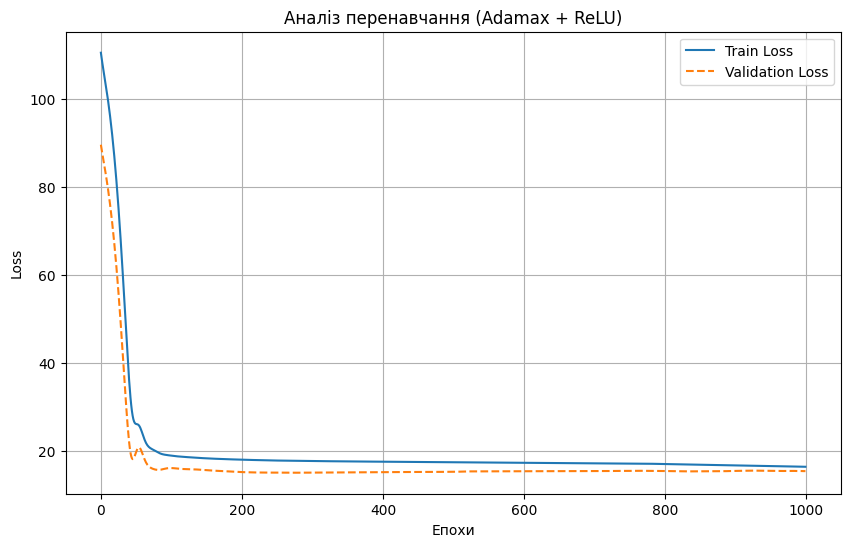

Optimizer: Nadam, Function: ReLU, Epoch [50/1000], Train Loss: 21.8983, Validation Loss: 16.9720
Optimizer: Nadam, Function: ReLU, Epoch [100/1000], Train Loss: 17.9453, Validation Loss: 14.9142
Optimizer: Nadam, Function: ReLU, Epoch [150/1000], Train Loss: 17.0694, Validation Loss: 14.7972
Optimizer: Nadam, Function: ReLU, Epoch [200/1000], Train Loss: 16.4204, Validation Loss: 14.9037
--- [INFO] Early stopping triggered at epoch 213 for Nadam ---
Optimizer: Nadam, Function: ReLU, Epoch [250/1000], Train Loss: 15.8886, Validation Loss: 15.2384
Optimizer: Nadam, Function: ReLU, Epoch [300/1000], Train Loss: 15.6746, Validation Loss: 15.7514
Optimizer: Nadam, Function: ReLU, Epoch [350/1000], Train Loss: 15.4793, Validation Loss: 16.3005
Optimizer: Nadam, Function: ReLU, Epoch [400/1000], Train Loss: 15.4654, Validation Loss: 16.6514
Optimizer: Nadam, Function: ReLU, Epoch [450/1000], Train Loss: 15.2846, Validation Loss: 17.3443
Optimizer: Nadam, Function: ReLU, Epoch [500/1000], Trai

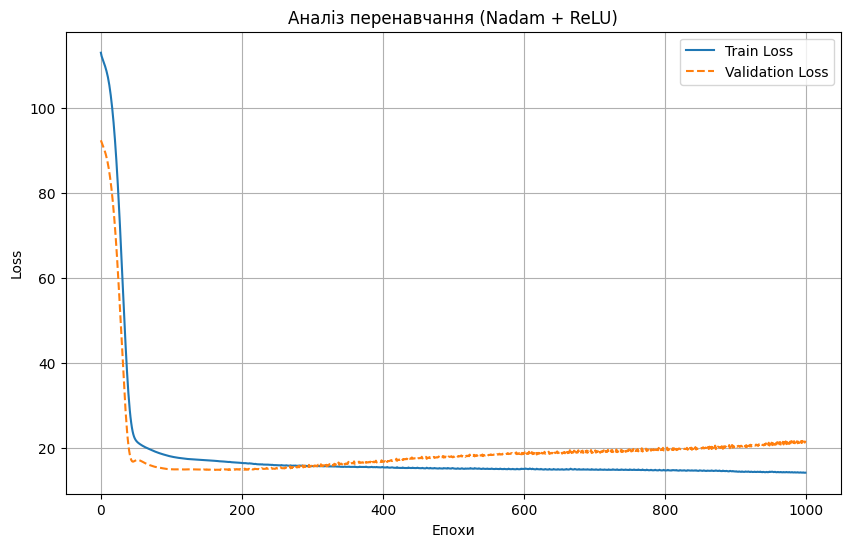

Optimizer: SGD, Function: Sigmoid, Epoch [50/1000], Train Loss: 26.5251, Validation Loss: 17.2116
Optimizer: SGD, Function: Sigmoid, Epoch [100/1000], Train Loss: 25.9640, Validation Loss: 16.8193
Optimizer: SGD, Function: Sigmoid, Epoch [150/1000], Train Loss: 25.1923, Validation Loss: 16.2268
Optimizer: SGD, Function: Sigmoid, Epoch [200/1000], Train Loss: 24.1157, Validation Loss: 15.3822
Optimizer: SGD, Function: Sigmoid, Epoch [250/1000], Train Loss: 22.7559, Validation Loss: 14.3301
Optimizer: SGD, Function: Sigmoid, Epoch [300/1000], Train Loss: 21.3687, Validation Loss: 13.3327
Optimizer: SGD, Function: Sigmoid, Epoch [350/1000], Train Loss: 20.3352, Validation Loss: 12.7190
Optimizer: SGD, Function: Sigmoid, Epoch [400/1000], Train Loss: 19.7673, Validation Loss: 12.5381
Optimizer: SGD, Function: Sigmoid, Epoch [450/1000], Train Loss: 19.5008, Validation Loss: 12.5978
--- [INFO] Early stopping triggered at epoch 455 for SGD ---
Optimizer: SGD, Function: Sigmoid, Epoch [500/100

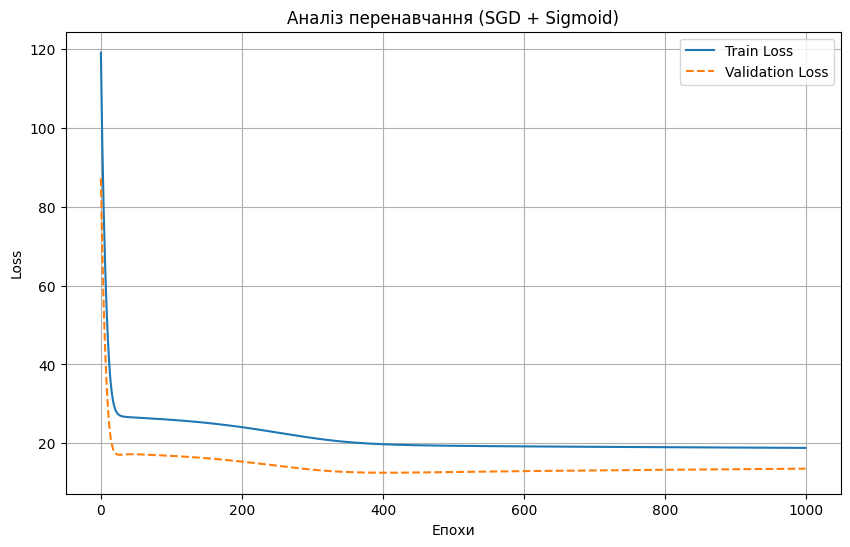

Optimizer: RMSprop, Function: Sigmoid, Epoch [50/1000], Train Loss: 23.4695, Validation Loss: 13.6062
Optimizer: RMSprop, Function: Sigmoid, Epoch [100/1000], Train Loss: 20.8238, Validation Loss: 12.2409
Optimizer: RMSprop, Function: Sigmoid, Epoch [150/1000], Train Loss: 19.6806, Validation Loss: 11.9919
Optimizer: RMSprop, Function: Sigmoid, Epoch [200/1000], Train Loss: 18.6867, Validation Loss: 12.4034
--- [INFO] Early stopping triggered at epoch 206 for RMSprop ---
Optimizer: RMSprop, Function: Sigmoid, Epoch [250/1000], Train Loss: 17.8621, Validation Loss: 13.0188
Optimizer: RMSprop, Function: Sigmoid, Epoch [300/1000], Train Loss: 17.1748, Validation Loss: 13.7231
Optimizer: RMSprop, Function: Sigmoid, Epoch [350/1000], Train Loss: 16.5158, Validation Loss: 14.5242
Optimizer: RMSprop, Function: Sigmoid, Epoch [400/1000], Train Loss: 15.8585, Validation Loss: 15.2362
Optimizer: RMSprop, Function: Sigmoid, Epoch [450/1000], Train Loss: 15.3120, Validation Loss: 15.3521
Optimizer

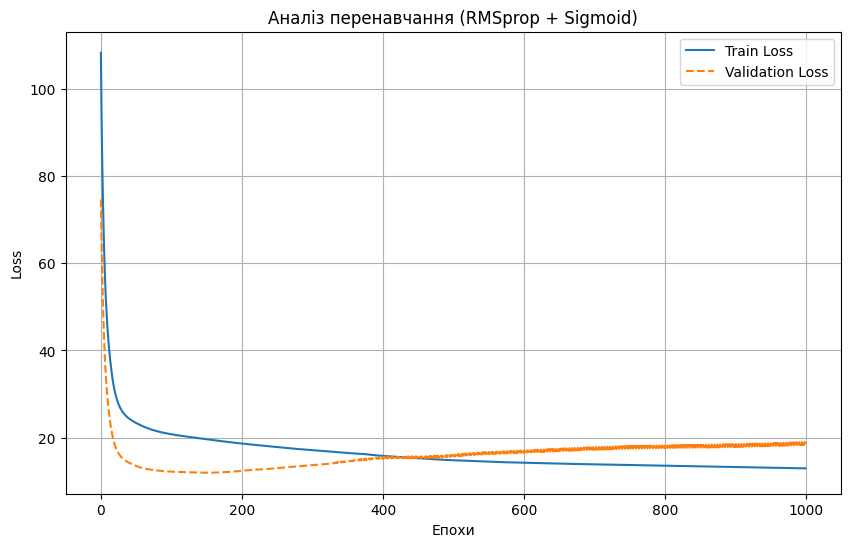

Optimizer: Adam, Function: Sigmoid, Epoch [50/1000], Train Loss: 45.6483, Validation Loss: 30.5955
Optimizer: Adam, Function: Sigmoid, Epoch [100/1000], Train Loss: 25.0935, Validation Loss: 14.7539
Optimizer: Adam, Function: Sigmoid, Epoch [150/1000], Train Loss: 22.8557, Validation Loss: 13.0924
Optimizer: Adam, Function: Sigmoid, Epoch [200/1000], Train Loss: 21.5786, Validation Loss: 12.2865
Optimizer: Adam, Function: Sigmoid, Epoch [250/1000], Train Loss: 20.8950, Validation Loss: 11.9331
Optimizer: Adam, Function: Sigmoid, Epoch [300/1000], Train Loss: 20.3837, Validation Loss: 11.6866
Optimizer: Adam, Function: Sigmoid, Epoch [350/1000], Train Loss: 19.8490, Validation Loss: 11.7343
--- [INFO] Early stopping triggered at epoch 365 for Adam ---
Optimizer: Adam, Function: Sigmoid, Epoch [400/1000], Train Loss: 19.3466, Validation Loss: 11.9910
Optimizer: Adam, Function: Sigmoid, Epoch [450/1000], Train Loss: 18.8025, Validation Loss: 12.3326
Optimizer: Adam, Function: Sigmoid, Epo

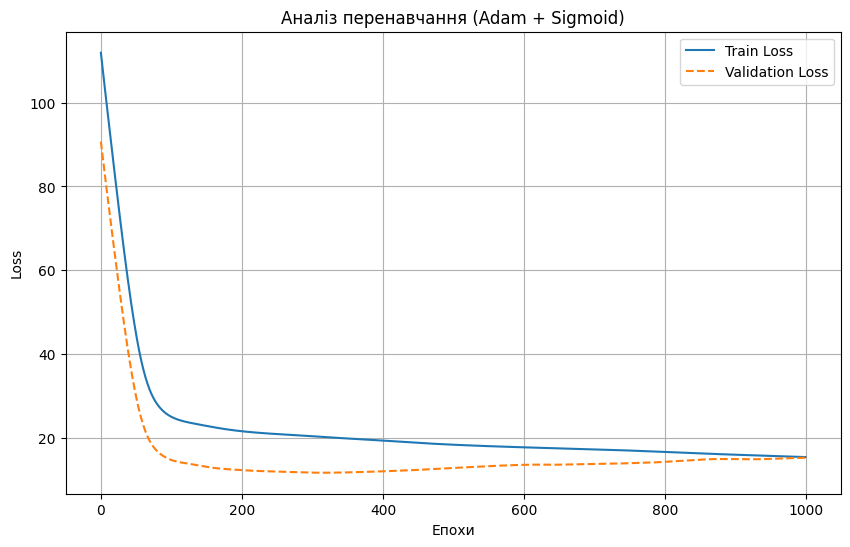

Optimizer: Adadelta, Function: Sigmoid, Epoch [50/1000], Train Loss: 77.0888, Validation Loss: 59.1770
Optimizer: Adadelta, Function: Sigmoid, Epoch [100/1000], Train Loss: 49.0439, Validation Loss: 34.0345
Optimizer: Adadelta, Function: Sigmoid, Epoch [150/1000], Train Loss: 33.9985, Validation Loss: 21.4025
Optimizer: Adadelta, Function: Sigmoid, Epoch [200/1000], Train Loss: 26.3546, Validation Loss: 15.7220
Optimizer: Adadelta, Function: Sigmoid, Epoch [250/1000], Train Loss: 23.4776, Validation Loss: 13.8892
Optimizer: Adadelta, Function: Sigmoid, Epoch [300/1000], Train Loss: 21.4325, Validation Loss: 12.4508
Optimizer: Adadelta, Function: Sigmoid, Epoch [350/1000], Train Loss: 19.8894, Validation Loss: 12.5655
--- [INFO] Early stopping triggered at epoch 368 for Adadelta ---
Optimizer: Adadelta, Function: Sigmoid, Epoch [400/1000], Train Loss: 18.7373, Validation Loss: 12.3050
Optimizer: Adadelta, Function: Sigmoid, Epoch [450/1000], Train Loss: 17.1395, Validation Loss: 12.9021

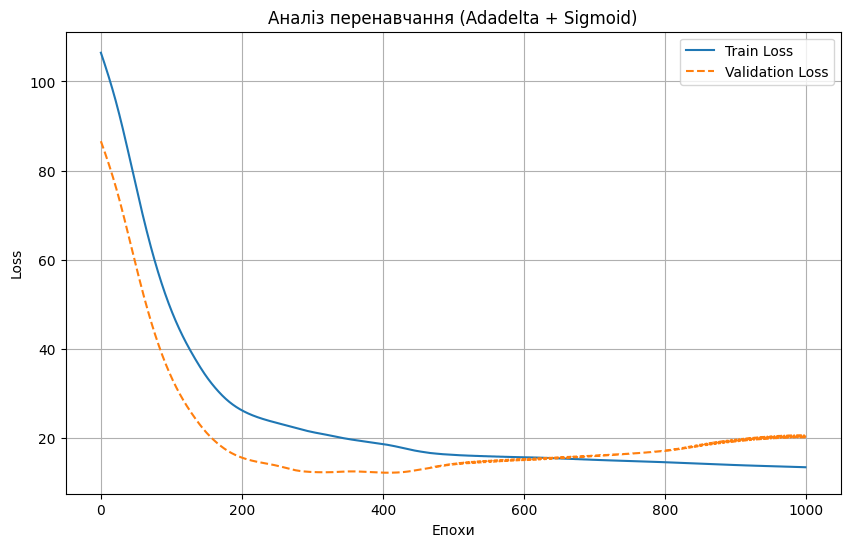

Optimizer: Adagrad, Function: Sigmoid, Epoch [50/1000], Train Loss: 86.3646, Validation Loss: 68.0709
Optimizer: Adagrad, Function: Sigmoid, Epoch [100/1000], Train Loss: 77.8664, Validation Loss: 60.3012
Optimizer: Adagrad, Function: Sigmoid, Epoch [150/1000], Train Loss: 71.4825, Validation Loss: 54.4969
Optimizer: Adagrad, Function: Sigmoid, Epoch [200/1000], Train Loss: 66.4544, Validation Loss: 49.9451
Optimizer: Adagrad, Function: Sigmoid, Epoch [250/1000], Train Loss: 62.3649, Validation Loss: 46.2552
Optimizer: Adagrad, Function: Sigmoid, Epoch [300/1000], Train Loss: 58.9319, Validation Loss: 43.1675
Optimizer: Adagrad, Function: Sigmoid, Epoch [350/1000], Train Loss: 55.9587, Validation Loss: 40.5031
Optimizer: Adagrad, Function: Sigmoid, Epoch [400/1000], Train Loss: 53.3112, Validation Loss: 38.1414
Optimizer: Adagrad, Function: Sigmoid, Epoch [450/1000], Train Loss: 50.9110, Validation Loss: 36.0127
Optimizer: Adagrad, Function: Sigmoid, Epoch [500/1000], Train Loss: 48.72

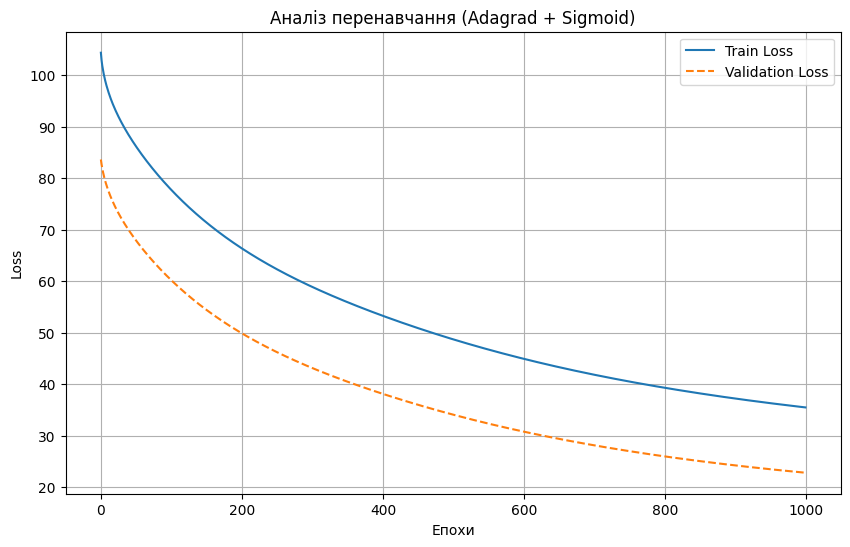

Optimizer: Adamax, Function: Sigmoid, Epoch [50/1000], Train Loss: 44.1932, Validation Loss: 29.5866
Optimizer: Adamax, Function: Sigmoid, Epoch [100/1000], Train Loss: 27.1723, Validation Loss: 16.2765
Optimizer: Adamax, Function: Sigmoid, Epoch [150/1000], Train Loss: 24.0417, Validation Loss: 14.0750
Optimizer: Adamax, Function: Sigmoid, Epoch [200/1000], Train Loss: 22.8767, Validation Loss: 13.0834
Optimizer: Adamax, Function: Sigmoid, Epoch [250/1000], Train Loss: 22.0734, Validation Loss: 12.5870
Optimizer: Adamax, Function: Sigmoid, Epoch [300/1000], Train Loss: 21.5028, Validation Loss: 12.3273
Optimizer: Adamax, Function: Sigmoid, Epoch [350/1000], Train Loss: 21.0992, Validation Loss: 12.1073
Optimizer: Adamax, Function: Sigmoid, Epoch [400/1000], Train Loss: 20.7904, Validation Loss: 11.9265
Optimizer: Adamax, Function: Sigmoid, Epoch [450/1000], Train Loss: 20.5277, Validation Loss: 11.7865
Optimizer: Adamax, Function: Sigmoid, Epoch [500/1000], Train Loss: 20.2628, Valida

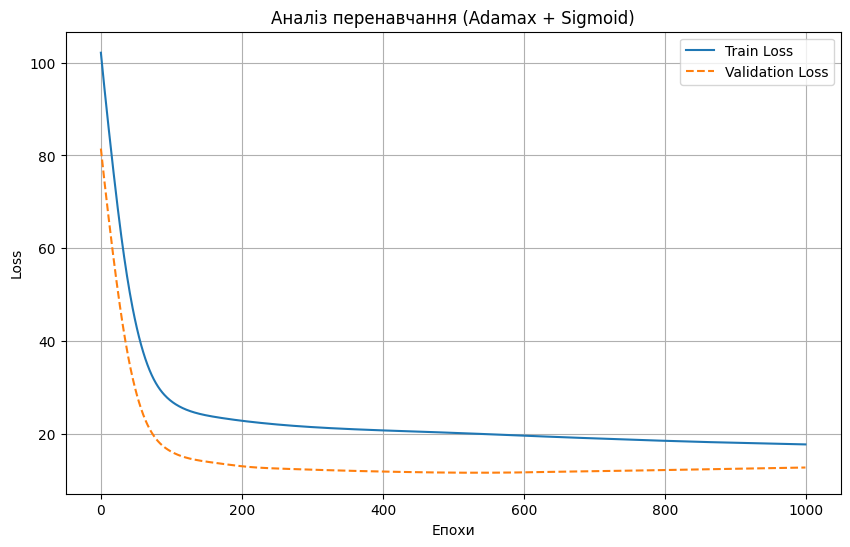

Optimizer: Nadam, Function: Sigmoid, Epoch [50/1000], Train Loss: 39.1656, Validation Loss: 25.3189
Optimizer: Nadam, Function: Sigmoid, Epoch [100/1000], Train Loss: 25.3840, Validation Loss: 15.0616
Optimizer: Nadam, Function: Sigmoid, Epoch [150/1000], Train Loss: 22.9118, Validation Loss: 13.1209
Optimizer: Nadam, Function: Sigmoid, Epoch [200/1000], Train Loss: 21.5934, Validation Loss: 12.3001
Optimizer: Nadam, Function: Sigmoid, Epoch [250/1000], Train Loss: 20.9155, Validation Loss: 11.9111
Optimizer: Nadam, Function: Sigmoid, Epoch [300/1000], Train Loss: 20.5775, Validation Loss: 11.7964
Optimizer: Nadam, Function: Sigmoid, Epoch [350/1000], Train Loss: 20.3522, Validation Loss: 11.7401
Optimizer: Nadam, Function: Sigmoid, Epoch [400/1000], Train Loss: 19.9672, Validation Loss: 11.6238
Optimizer: Nadam, Function: Sigmoid, Epoch [450/1000], Train Loss: 19.3159, Validation Loss: 11.8302
--- [INFO] Early stopping triggered at epoch 469 for Nadam ---
Optimizer: Nadam, Function: S

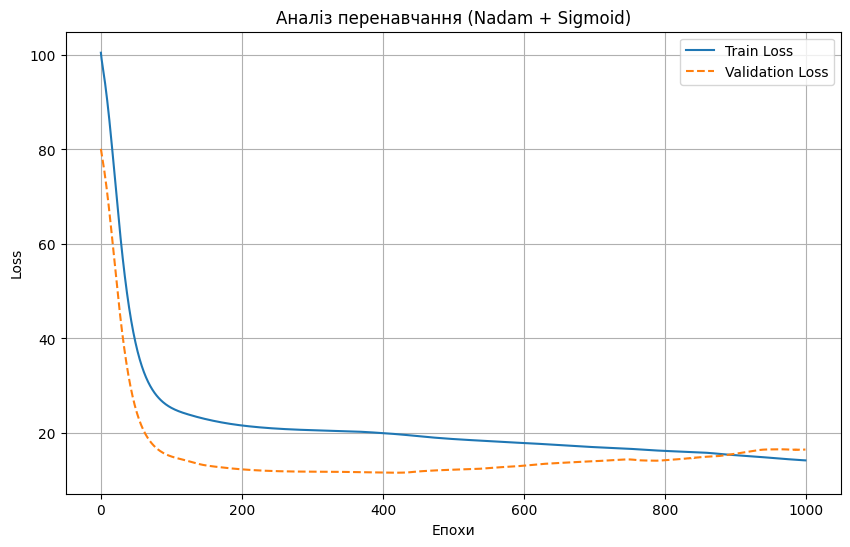

Optimizer: SGD, Function: Tanh, Epoch [50/1000], Train Loss: 20.7522, Validation Loss: 12.3541
Optimizer: SGD, Function: Tanh, Epoch [100/1000], Train Loss: 19.3438, Validation Loss: 12.1786
--- [INFO] Early stopping triggered at epoch 136 for SGD ---
Optimizer: SGD, Function: Tanh, Epoch [150/1000], Train Loss: 18.6025, Validation Loss: 12.4571
Optimizer: SGD, Function: Tanh, Epoch [200/1000], Train Loss: 18.0698, Validation Loss: 12.8802
Optimizer: SGD, Function: Tanh, Epoch [250/1000], Train Loss: 17.5901, Validation Loss: 13.3170
Optimizer: SGD, Function: Tanh, Epoch [300/1000], Train Loss: 17.1579, Validation Loss: 13.7474
Optimizer: SGD, Function: Tanh, Epoch [350/1000], Train Loss: 16.8140, Validation Loss: 14.1429
Optimizer: SGD, Function: Tanh, Epoch [400/1000], Train Loss: 16.5300, Validation Loss: 14.4174
Optimizer: SGD, Function: Tanh, Epoch [450/1000], Train Loss: 16.2630, Validation Loss: 14.6124
Optimizer: SGD, Function: Tanh, Epoch [500/1000], Train Loss: 16.0132, Valid

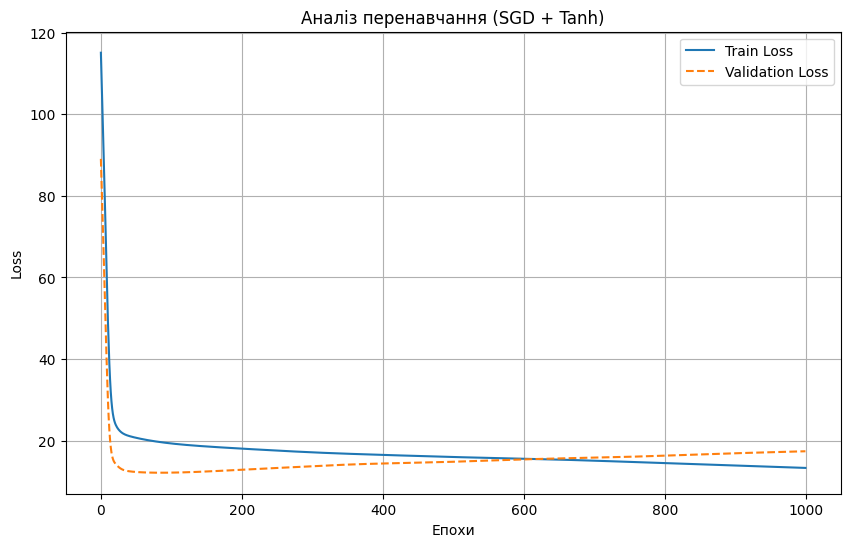

Optimizer: RMSprop, Function: Tanh, Epoch [50/1000], Train Loss: 22.3808, Validation Loss: 13.0138
Optimizer: RMSprop, Function: Tanh, Epoch [100/1000], Train Loss: 18.6456, Validation Loss: 12.6365
--- [INFO] Early stopping triggered at epoch 131 for RMSprop ---
Optimizer: RMSprop, Function: Tanh, Epoch [150/1000], Train Loss: 16.2343, Validation Loss: 14.3587
Optimizer: RMSprop, Function: Tanh, Epoch [200/1000], Train Loss: 14.5554, Validation Loss: 15.7363
Optimizer: RMSprop, Function: Tanh, Epoch [250/1000], Train Loss: 13.6270, Validation Loss: 16.7372
Optimizer: RMSprop, Function: Tanh, Epoch [300/1000], Train Loss: 12.9361, Validation Loss: 17.6761
Optimizer: RMSprop, Function: Tanh, Epoch [350/1000], Train Loss: 12.5141, Validation Loss: 18.4534
Optimizer: RMSprop, Function: Tanh, Epoch [400/1000], Train Loss: 12.1787, Validation Loss: 18.8193
Optimizer: RMSprop, Function: Tanh, Epoch [450/1000], Train Loss: 11.6320, Validation Loss: 19.7146
Optimizer: RMSprop, Function: Tanh, 

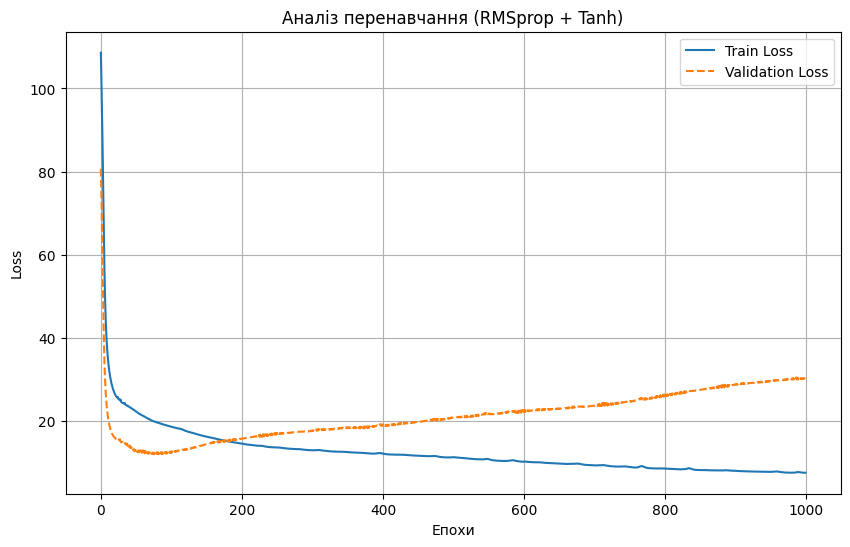

Optimizer: Adam, Function: Tanh, Epoch [50/1000], Train Loss: 31.7362, Validation Loss: 19.4410
Optimizer: Adam, Function: Tanh, Epoch [100/1000], Train Loss: 23.6668, Validation Loss: 14.8286
Optimizer: Adam, Function: Tanh, Epoch [150/1000], Train Loss: 20.6122, Validation Loss: 12.8783
Optimizer: Adam, Function: Tanh, Epoch [200/1000], Train Loss: 18.7715, Validation Loss: 12.8519
--- [INFO] Early stopping triggered at epoch 232 for Adam ---
Optimizer: Adam, Function: Tanh, Epoch [250/1000], Train Loss: 16.8406, Validation Loss: 13.6751
Optimizer: Adam, Function: Tanh, Epoch [300/1000], Train Loss: 15.6041, Validation Loss: 14.9878
Optimizer: Adam, Function: Tanh, Epoch [350/1000], Train Loss: 14.8123, Validation Loss: 16.2808
Optimizer: Adam, Function: Tanh, Epoch [400/1000], Train Loss: 14.0823, Validation Loss: 16.9681
Optimizer: Adam, Function: Tanh, Epoch [450/1000], Train Loss: 13.3593, Validation Loss: 16.9778
Optimizer: Adam, Function: Tanh, Epoch [500/1000], Train Loss: 12.

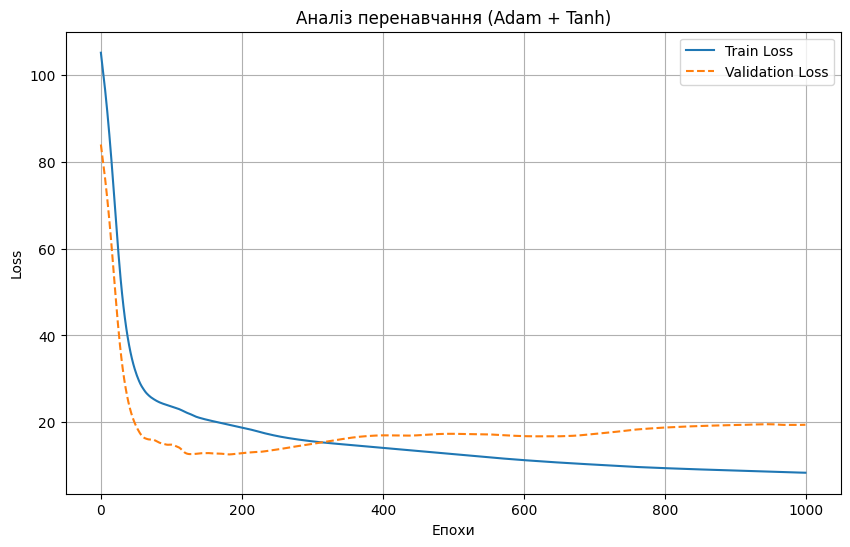

Optimizer: Adadelta, Function: Tanh, Epoch [50/1000], Train Loss: 31.6245, Validation Loss: 19.2253
Optimizer: Adadelta, Function: Tanh, Epoch [100/1000], Train Loss: 22.2395, Validation Loss: 12.9127
Optimizer: Adadelta, Function: Tanh, Epoch [150/1000], Train Loss: 19.7627, Validation Loss: 12.6265
Optimizer: Adadelta, Function: Tanh, Epoch [200/1000], Train Loss: 18.5698, Validation Loss: 13.1011
--- [INFO] Early stopping triggered at epoch 203 for Adadelta ---
Optimizer: Adadelta, Function: Tanh, Epoch [250/1000], Train Loss: 17.3183, Validation Loss: 14.3318
Optimizer: Adadelta, Function: Tanh, Epoch [300/1000], Train Loss: 16.3090, Validation Loss: 15.8039
Optimizer: Adadelta, Function: Tanh, Epoch [350/1000], Train Loss: 15.4654, Validation Loss: 17.0504
Optimizer: Adadelta, Function: Tanh, Epoch [400/1000], Train Loss: 14.7244, Validation Loss: 18.1496
Optimizer: Adadelta, Function: Tanh, Epoch [450/1000], Train Loss: 14.1452, Validation Loss: 19.0286
Optimizer: Adadelta, Funct

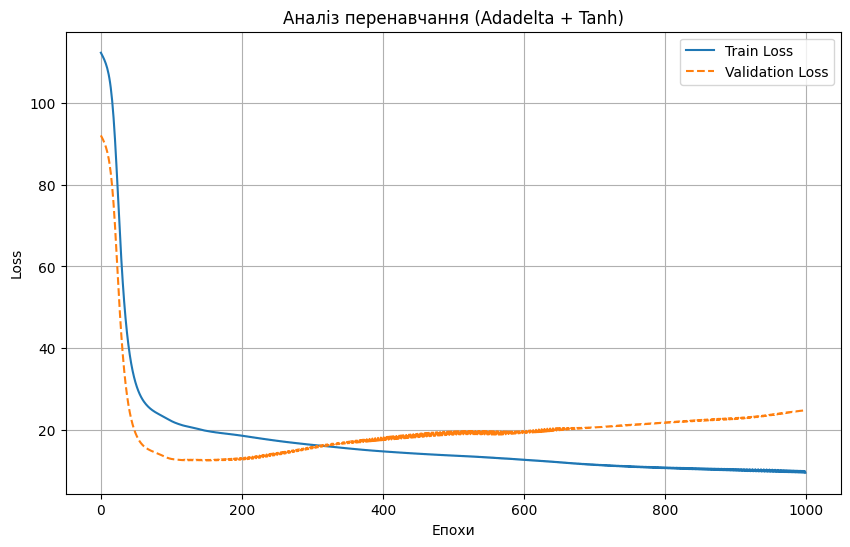

Optimizer: Adagrad, Function: Tanh, Epoch [50/1000], Train Loss: 80.5808, Validation Loss: 63.2802
Optimizer: Adagrad, Function: Tanh, Epoch [100/1000], Train Loss: 64.4758, Validation Loss: 48.2421
Optimizer: Adagrad, Function: Tanh, Epoch [150/1000], Train Loss: 54.9626, Validation Loss: 39.6176
Optimizer: Adagrad, Function: Tanh, Epoch [200/1000], Train Loss: 48.9959, Validation Loss: 34.3233
Optimizer: Adagrad, Function: Tanh, Epoch [250/1000], Train Loss: 44.8808, Validation Loss: 30.7311
Optimizer: Adagrad, Function: Tanh, Epoch [300/1000], Train Loss: 41.8373, Validation Loss: 28.1122
Optimizer: Adagrad, Function: Tanh, Epoch [350/1000], Train Loss: 39.4756, Validation Loss: 26.1070
Optimizer: Adagrad, Function: Tanh, Epoch [400/1000], Train Loss: 37.5795, Validation Loss: 24.5176
Optimizer: Adagrad, Function: Tanh, Epoch [450/1000], Train Loss: 36.0187, Validation Loss: 23.2253
Optimizer: Adagrad, Function: Tanh, Epoch [500/1000], Train Loss: 34.7087, Validation Loss: 22.1537
O

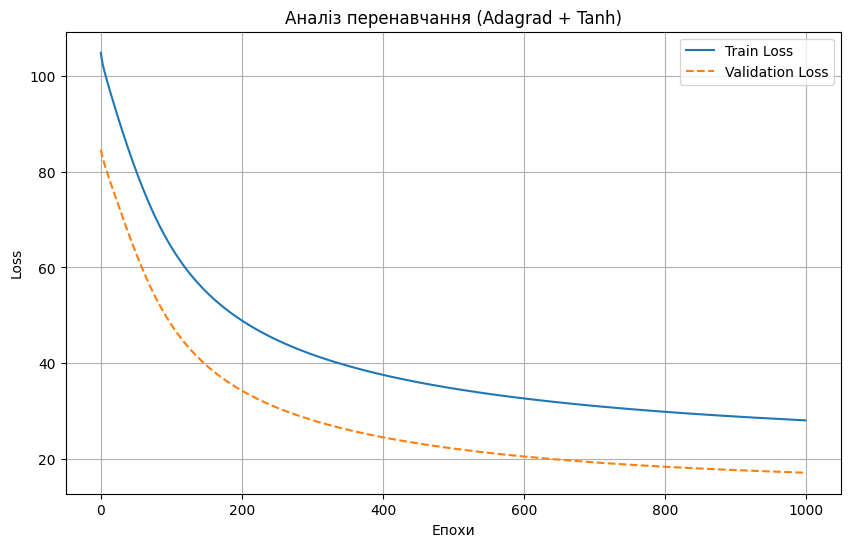

Optimizer: Adamax, Function: Tanh, Epoch [50/1000], Train Loss: 37.6037, Validation Loss: 24.0049
Optimizer: Adamax, Function: Tanh, Epoch [100/1000], Train Loss: 25.3353, Validation Loss: 15.2810
Optimizer: Adamax, Function: Tanh, Epoch [150/1000], Train Loss: 23.3483, Validation Loss: 14.1863
Optimizer: Adamax, Function: Tanh, Epoch [200/1000], Train Loss: 21.6224, Validation Loss: 12.8263
Optimizer: Adamax, Function: Tanh, Epoch [250/1000], Train Loss: 20.1403, Validation Loss: 13.0514
--- [INFO] Early stopping triggered at epoch 271 for Adamax ---
Optimizer: Adamax, Function: Tanh, Epoch [300/1000], Train Loss: 19.3961, Validation Loss: 13.2594
Optimizer: Adamax, Function: Tanh, Epoch [350/1000], Train Loss: 18.5100, Validation Loss: 13.0333
Optimizer: Adamax, Function: Tanh, Epoch [400/1000], Train Loss: 17.5512, Validation Loss: 13.0387
Optimizer: Adamax, Function: Tanh, Epoch [450/1000], Train Loss: 16.8216, Validation Loss: 13.4195
Optimizer: Adamax, Function: Tanh, Epoch [500/

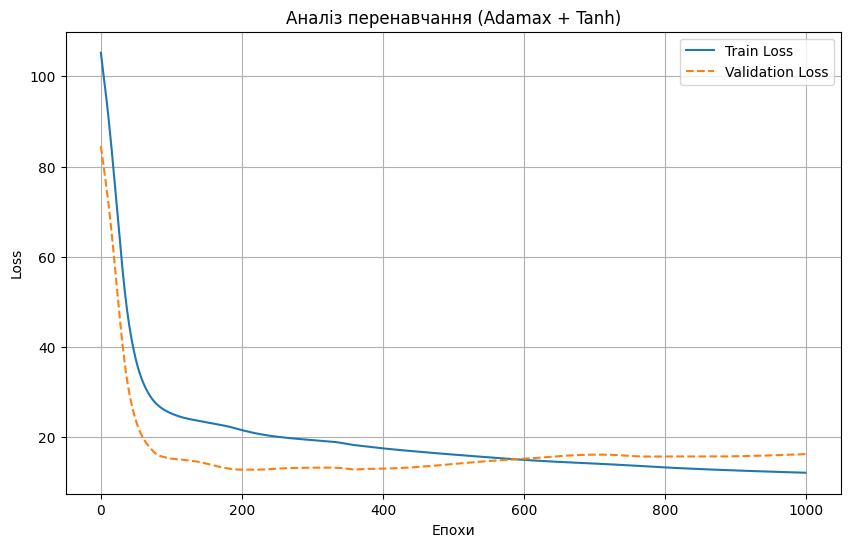

Optimizer: Nadam, Function: Tanh, Epoch [50/1000], Train Loss: 32.7932, Validation Loss: 20.2354
Optimizer: Nadam, Function: Tanh, Epoch [100/1000], Train Loss: 22.9741, Validation Loss: 13.8865
Optimizer: Nadam, Function: Tanh, Epoch [150/1000], Train Loss: 19.6963, Validation Loss: 13.1888
--- [INFO] Early stopping triggered at epoch 187 for Nadam ---
Optimizer: Nadam, Function: Tanh, Epoch [200/1000], Train Loss: 17.6565, Validation Loss: 13.4574
Optimizer: Nadam, Function: Tanh, Epoch [250/1000], Train Loss: 16.2244, Validation Loss: 14.1962
Optimizer: Nadam, Function: Tanh, Epoch [300/1000], Train Loss: 15.3043, Validation Loss: 14.9908
Optimizer: Nadam, Function: Tanh, Epoch [350/1000], Train Loss: 14.5421, Validation Loss: 15.7454
Optimizer: Nadam, Function: Tanh, Epoch [400/1000], Train Loss: 13.9328, Validation Loss: 15.6176
Optimizer: Nadam, Function: Tanh, Epoch [450/1000], Train Loss: 13.4712, Validation Loss: 15.6934
Optimizer: Nadam, Function: Tanh, Epoch [500/1000], Trai

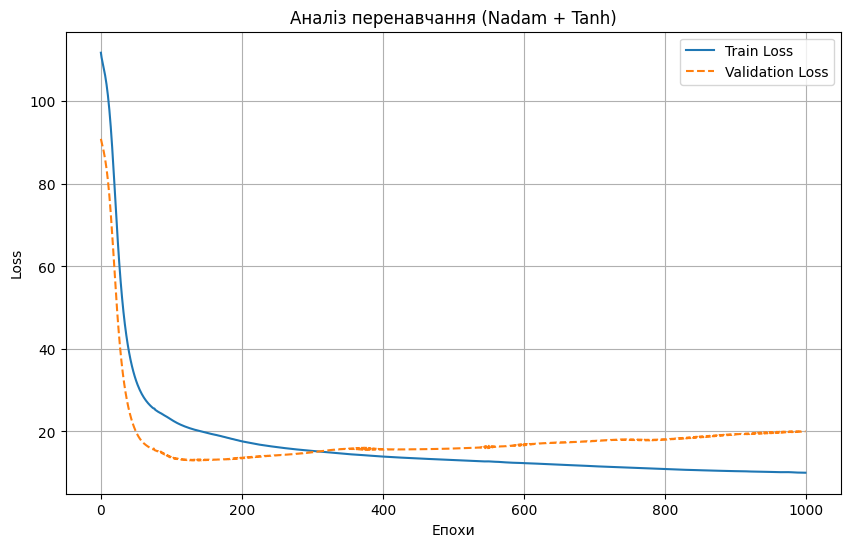

In [103]:
for activation_function_name in activation_function_names:
    for optimizer in optimizer_names:
        perform_learning_analysis(1000, optimizer, activation_function_name)
        

In [104]:
best_model.eval()

with torch.no_grad():
    test_predictions = best_model(X_test_scaled_tensor)
    test_r2 = R2Score()(test_predictions, y_test_tensor)
    test_mae = MeanAbsoluteError()(test_predictions, y_test_tensor)
    test_mse = MeanSquaredError()(test_predictions, y_test_tensor)

print("\n" + "="*30)
print("ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ТЕСТОВІЙ ВИБІРЦІ (Wages)")
print(f"R2-Score: {test_r2.item():.4f}")
print(f"MAE (Середня похибка): {test_mae.item():.4f}")
print(f"MSE: {test_mse.item():.4f}")
print("="*30)


ФІНАЛЬНІ РЕЗУЛЬТАТИ НА ТЕСТОВІЙ ВИБІРЦІ (Wages)
R2-Score: 0.2890
MAE (Середня похибка): 3.8734
MSE: 29.2902


In [105]:
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

In [106]:
classic_models = {
    'XGBoost': XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42),
    'LinearRegression': LinearRegression()
}

print("\nНавчання класичних моделей ML...")

for name, model in classic_models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_val_scaled)
    
    predictions_tensor = torch.tensor(predictions, dtype=torch.float32).reshape(-1, 1)
    
    r2 = R2Score()(predictions_tensor, y_val_tensor).item()
    mae = MeanAbsoluteError()(predictions_tensor, y_val_tensor).item()
    mse = MeanSquaredError()(predictions_tensor, y_val_tensor).item()
    
    results.append({
        'Activation': 'Classical ML',
        'Optimizer': name,
        'MSE': mse,
        'R2-Score': r2
    })
    print(f"{name} завершено. R2-Score: {r2:.4f}")

results_df = pd.DataFrame(results)
print("\nФІНАЛЬНЕ ПОРІВНЯННЯ МОДЕЛЕЙ:")
print(results_df.sort_values(by='R2-Score', ascending=False))


Навчання класичних моделей ML...
XGBoost завершено. R2-Score: -0.4248
RandomForest завершено. R2-Score: -0.1316
LinearRegression завершено. R2-Score: 0.1966

ФІНАЛЬНЕ ПОРІВНЯННЯ МОДЕЛЕЙ:
      Activation         Optimizer        MSE  R2-Score
12       Sigmoid            Adamax  11.625456  0.317216
9        Sigmoid              Adam  11.883797  0.302043
13       Sigmoid             Nadam  11.967192  0.297145
16          Tanh              Adam  12.196157  0.283698
8        Sigmoid           RMSprop  12.331122  0.275771
17          Tanh          Adadelta  12.428507  0.270051
14          Tanh               SGD  12.501660  0.265755
10       Sigmoid          Adadelta  12.511224  0.265193
7        Sigmoid               SGD  12.609131  0.259443
19          Tanh            Adamax  12.748199  0.251275
20          Tanh             Nadam  13.094673  0.230926
15          Tanh           RMSprop  13.100023  0.230612
23  Classical ML  LinearRegression  13.679786  0.196561
2           ReLU            